# Automated Organoid Segmentation and Quantification

**Stereomicroscopy image analysis | Organoid formation efficiency (OFE) research**

**Computational workflow:** Ivey Sebastian (Scientific Computing, MPI-CBG)  
**Research collaboration:** Jinia Lilianty, postdoctoral researcher, Meri Huch research group  
**Original notebook:** v1.0 beta · December 2025

> **Scope:** This notebook detects candidate organoids, extracts image-based measurements, and summarizes object counts and areas. It does not independently calculate OFE percentages without experimental seeding information.

## Scientific context

Low-resolution stereomicroscopy images present difficult segmentation conditions: variable organoid size and shape, heterogeneous backgrounds, and touching structures. This workflow combines classical image preprocessing with two-scale Cellpose segmentation and post-processing to support more consistent, batch-based quantification.

**Reproducibility note:** This presentation edition reorganizes and documents the notebook only. **Every original Python code cell is retained unchanged**, including algorithm settings, paths, and plotting expressions.

## Workflow overview

```mermaid
flowchart TD
    A[Input stereomicroscopy images] --> B[Median filter, sharpening, contrast, Sobel]
    B --> C1[Cellpose: diameter 70 px]
    B --> C2[Cellpose: diameter 20 px]
    C1 --> D[Union of binary masks]
    C2 --> D
    D --> E[Separate touching objects]
    E --> F[Connected-component labeling]
    F --> G[Region-based feature extraction]
    G --> H[Area-based classification: 100 px threshold]
    H --> I[Per-image CSV tables]
    F --> J[Boundary overlays for visual QC]
    I --> K[Summary plots]
```

### Key implementation settings

| Stage | Original setting |
| --- | --- |
| Median filter | Disk radius 3 px |
| Sharpening | 3 × 3 kernel |
| Contrast | `alpha=2.0`, `beta=0` |
| Edge enhancement | Sobel |
| Segmentation | Cellpose `cyto`, CPU, diameters 70 and 20 px |
| Cellpose thresholds | `flow_threshold=0`, `cellprob_threshold=-2` |
| Post-processing | Mask union; `split_touching_objects`; pyclesperanto labeling |
| Area rule | `Success` for area ≥ 100 px; otherwise `Ambiguous` |

**Interpretation:** `Success` is the notebook's size-based label, not experimentally verified organoid identity. Measurements are in image pixels unless calibrated externally.

## 1. Environment and dependencies

The original notebook expects Python packages including NumPy, pandas, OpenCV, scikit-image, Matplotlib, Cellpose, pyclesperanto, and `napari-segment-blobs-and-things-with-membranes`.

The original environment creation command is preserved below. An `environment.yml` file must be supplied separately; it is not embedded in this notebook. Package compatibility depends on the original environment.

In [2]:
import os
import numpy as np
import pandas as pd
import cv2
from skimage import io, measure
from skimage.filters import sobel
from skimage.morphology import disk
from skimage.filters import rank as rank_filters
import matplotlib.pyplot as plt

from cellpose import models
import pyclesperanto_prototype as cle
from napari_segment_blobs_and_things_with_membranes import split_touching_objects

/Users/isebasti/opt/anaconda3/lib/python3.9/site-packages/napari/_qt/__init__.py:50: UserWarning: 

napari was tested with QT library `>=5.12.3`.
The version installed is 5.9.7. Please report any issues with
this specific QT version at https://github.com/Napari/napari/issues.
  warn(message=warn_message)


## 2. Segmentation and measurement functions

The following code defines image loading and preprocessing, two Cellpose inference passes, mask union, touching-object processing, connected-component labeling, feature extraction, CSV export, and overlay generation.

**Per-object CSV fields:** area, maximum/minimum/mean intensity, major-axis length, and the size-based `type` classification. Objects marked `Ambiguous` are excluded from exported CSV tables.

**Batch behavior:** Input images are discovered recursively. Existing CSV + overlay pairs are skipped. Processing failures are reported to the console.

In [3]:
# -----------------------------
# Utility - robust intensity getter (skimage version tolerant)
# -----------------------------
def _get_intensity(p, names):
    for n in names:
        if hasattr(p, n):
            return getattr(p, n)
    return np.nan


# -----------------------------
# Process a single image
# -----------------------------
def process_single_image(img_path, model, results_folder, show_plots=False):
    print(f"\nProcessing: {img_path}")
    base = os.path.splitext(os.path.basename(img_path))[0]
    csv_path = os.path.join(results_folder, f"{base}.csv")
    overlay_path = os.path.join(results_folder, f"{base}_overlay.png")

    # --------------------------------------------------
    # SKIP if both output files already exist
    # --------------------------------------------------
    if os.path.exists(csv_path) and os.path.exists(overlay_path):
        print(f"Skipping {img_path} → results already exist.")
        return csv_path, overlay_path, None
    # Load the image
    img = io.imread(img_path)

    # Use first channel if multi-channel
    if img.ndim == 3:
        image = img[:, :, 0]
    else:
        image = img.copy()

    # Ensure uint8 for median filter
    if img.ndim == 3:
    # If RGB → convert to 1-channel using first channel (like your original code)
        image = img[:, :, 0]
    elif img.ndim == 2:
        image = img
    else:
        raise ValueError("Unsupported image shape: {}".format(img.shape))

    #image = image.astype(np.uint16)  # keep dtype safe
    
    
    if image.dtype != np.uint8:
        if np.issubdtype(image.dtype, np.floating):
            img_uint8 = (255 * (image - image.min()) / (image.ptp() if image.ptp() != 0 else 1)).astype(np.uint8)
        else:
            img_uint8 = np.clip(image, 0, 255).astype(np.uint8)
    else:
        img_uint8 = image

    # -----------------------------
    # Median filter (disk radius 3)
    # -----------------------------
    selem = disk(3)
    median = rank_filters.median(img_uint8, selem)

    # -----------------------------
    # Sharpen with kernel
    # -----------------------------
    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]])
    img_br = cv2.filter2D(median, -1, kernel)

    # -----------------------------
    # Contrast adjustment
    # -----------------------------
    alpha = 2.0
    beta = 0
    adjusted = cv2.convertScaleAbs(img_br, alpha=alpha, beta=beta)

    # -----------------------------
    # Sobel edge detection
    # -----------------------------
    image3 = sobel(adjusted.astype(np.float32))

    # -----------------------------
    # Cellpose segmentation (two diameters)
    # -----------------------------
    try:
        masks_70, _, _, _ = model.eval(image3, diameter=70, channels=None, flow_threshold=0, cellprob_threshold=-2)
    except:
        masks_70 = np.zeros_like(image3)

    try:
        masks_20, _, _, _ = model.eval(image3, diameter=20, channels=None, flow_threshold=0, cellprob_threshold=-2)
    except:
        masks_20 = np.zeros_like(image3)

    masks_70 = (np.asarray(masks_70) > 0)
    masks_20 = (np.asarray(masks_20) > 0)

    # Combine masks
    combined = np.bitwise_or(masks_70, masks_20)
    binary = combined > 0
    split_objects = split_touching_objects(binary)
    # -----------------------------
    # Label via cle
    # -----------------------------
    labeled = cle.connected_components_labeling_box(split_objects)
    labeled_np = np.asarray(labeled)

    # Cell borders for overlay
    try:
        cell_borders = cle.reduce_labels_to_label_edges(labeled)
    except:
        from skimage.segmentation import find_boundaries
        cell_borders = find_boundaries(labeled_np)

    num_labels = int(np.max(labeled_np))
    print(f"  → Objects detected: {num_labels}")

    # -----------------------------
    # Regionprops
    # -----------------------------
    properties = measure.regionprops(labeled_np, intensity_image=image)

    stats = {
        'area': [p.area for p in properties],
        'max': [_get_intensity(p, ['max_intensity', 'intensity_max']) for p in properties],
        'min': [_get_intensity(p, ['min_intensity', 'intensity_min']) for p in properties],
        'mean': [_get_intensity(p, ['mean_intensity', 'intensity_mean']) for p in properties],
        'major_axis': [p.major_axis_length for p in properties]
    }

    # Type classification
    typ = ['Success' if p.area >= 100 else 'Ambiguous' for p in properties]

    df = pd.DataFrame(stats)
    df['type'] = typ
    df.index += 1

    # Filter ambiguous rows
    df_filtered = df[df['type'] != 'Ambiguous']

    # -----------------------------
    # Save CSV
    # -----------------------------
    base = os.path.splitext(os.path.basename(img_path))[0]
    csv_path = os.path.join(results_folder, f"{base}.csv")
    df_filtered.to_csv(csv_path, index=True, index_label='index')
    print(f"  → Saved CSV: {csv_path}")

    # -----------------------------
    # Save overlay image robustly
    # -----------------------------
    # Convert grayscale to 3-channel if needed
    if image.ndim == 2:
        overlay = np.stack([image, image, image], axis=-1)
    elif image.ndim == 3 and image.shape[2] >= 3:
        overlay = image[:, :, :3].copy()
    else:
        overlay = np.stack([image, image, image], axis=-1)

    # Ensure uint8
    if overlay.dtype != np.uint8:
        overlay = np.clip(overlay, 0, 255).astype(np.uint8)

    # Draw red contours where cell_borders > 0
    borders_np = np.asarray(cell_borders)
    overlay[borders_np > 0] = [255, 0, 0]  # red

    # Save overlay with skimage.io.imsave
    overlay_path = os.path.join(results_folder, f"{base}_overlay.png")
    io.imsave(overlay_path, overlay)
    print(f"  → Saved overlay: {overlay_path}")
    
    return csv_path, overlay_path, num_labels

# -----------------------------
# Process a full folder recursively
# -----------------------------
def analyze_folder(main_folder, show_plots=False):
    results_folder = os.path.join(main_folder, "results")
    os.makedirs(results_folder, exist_ok=True)

    print("\nLoading Cellpose model (cyto)...")
    model = models.Cellpose(gpu=False, model_type='cyto')
    print("Cellpose model loaded.\n")

    image_exts = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp", ".ome.tif", ".ome.tiff")
    results = []

    for root, dirs, files in os.walk(main_folder):
        if os.path.abspath(root) == os.path.abspath(results_folder):
            continue

        for fname in files:
            if fname.lower().endswith(image_exts):
                img_path = os.path.join(root, fname)
                try:
                    csv_path, overlay_path, count = process_single_image(
                        img_path, model, results_folder, show_plots
                    )
                    results.append((img_path, csv_path, overlay_path, count))
                except Exception as e:
                    print(f"Error processing {img_path}: {e}")

    print("\nAll processing complete.")
    return results



## 3. Run the batch analysis

**Before running:** Update `MAIN_FOLDER` in the following *unchanged original code cell* to point to your local image directory. The notebook writes a `results/` subfolder there.

**Privacy note:** The original internal filesystem path is retained for algorithm-preserving reproducibility; replace it before public use if necessary.

In [4]:
# -----------------------------
# RUN SCRIPT
# -----------------------------
if __name__ == "__main__":
    MAIN_FOLDER = r"/Volumes/ipf/public/Data/Jinia/"
    analyze_folder(MAIN_FOLDER, show_plots=False)



Loading Cellpose model (cyto)...
Cellpose model loaded.


Processing: /Volumes/ipf/public/Data/Jinia/New images/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w2.tif
  → Objects detected: 368
  → Saved CSV: /Volumes/ipf/public/Data/Jinia/results/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w2.csv
  → Saved overlay: /Volumes/ipf/public/Data/Jinia/results/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w2_overlay.png

Processing: /Volumes/ipf/public/Data/Jinia/New images/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w1.tif
  → Objects detected: 711
  → Saved CSV: /Volumes/ipf/public/Data/Jinia/results/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w1.csv
  → Saved overlay: /Volumes/ipf/public/Data/Jinia/results/20251205 PHH48 thawed D22 Cryojin  48wp 1.25X w1_overlay.png

Processing: /Volumes/ipf/public/Data/Jinia/New images/20251205 PHH48 thawed D22 Celprogen 48wp 1.25X w3.tif
  → Objects detected: 478
  → Saved CSV: /Volumes/ipf/public/Data/Jinia/results/20251205 PHH48 thawed D22 Celprog

## 4. Collect per-image measurements

This cell reads CSV outputs from the configured `results_folder` and prepares two summaries: number of retained objects per image (`segment_counts`) and summed retained-object area (`total_area`).

Update `results_folder` to match your local output location before execution.

In [5]:
# Path to the results folder where all CSVs are saved
results_folder = r"/Volumes/ipf/public/Data/Jinia/results"

# List all CSV files
csv_files = [f for f in os.listdir(results_folder) if f.lower().endswith(".csv")]

file_names = []
segment_counts = []
total_area = []

for csv_file in csv_files:
    csv_path = os.path.join(results_folder, csv_file)
    df = pd.read_csv(csv_path)
    file_names.append(csv_file)
    segment_counts.append(len(df))
    if 'area' in df.columns:
        total_area.append(df['area'].sum())
    else:
        total_area.append(0)

# Sort alphabetically
sorted_idx = sorted(range(len(file_names)), key=lambda i: file_names[i])
file_names = [file_names[i] for i in sorted_idx]
segment_counts = [segment_counts[i] for i in sorted_idx]
total_area = [total_area[i] for i in sorted_idx]


## 5. Visualize detected object counts

Bar chart of retained segmentation objects per image.

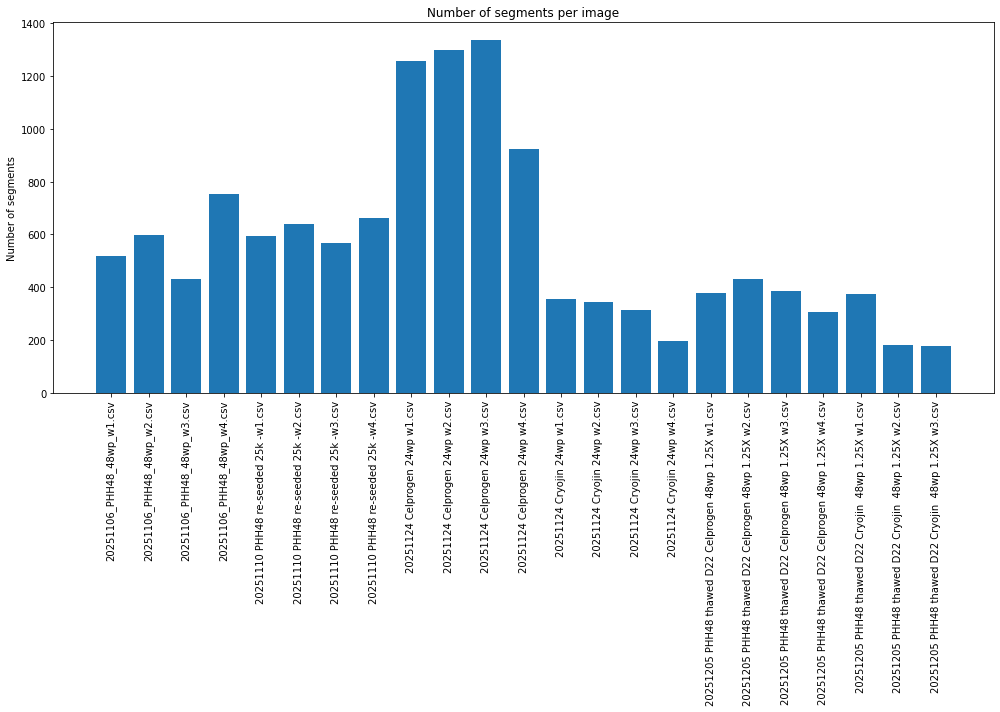

In [10]:
plt.figure(figsize=(14, 10))

plt.bar(file_names, segment_counts)
plt.ylabel('Number of segments')
plt.title('Number of segments per image')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## 6. Original total-area plot (code preserved)

**Known presentation inconsistency:** The following original code uses `segment_counts` for the bar heights even though the title and y-axis say *Total segment area*. To display total area, the plotted variable would need to be `total_area`. This notebook intentionally leaves the original code unchanged, as requested.

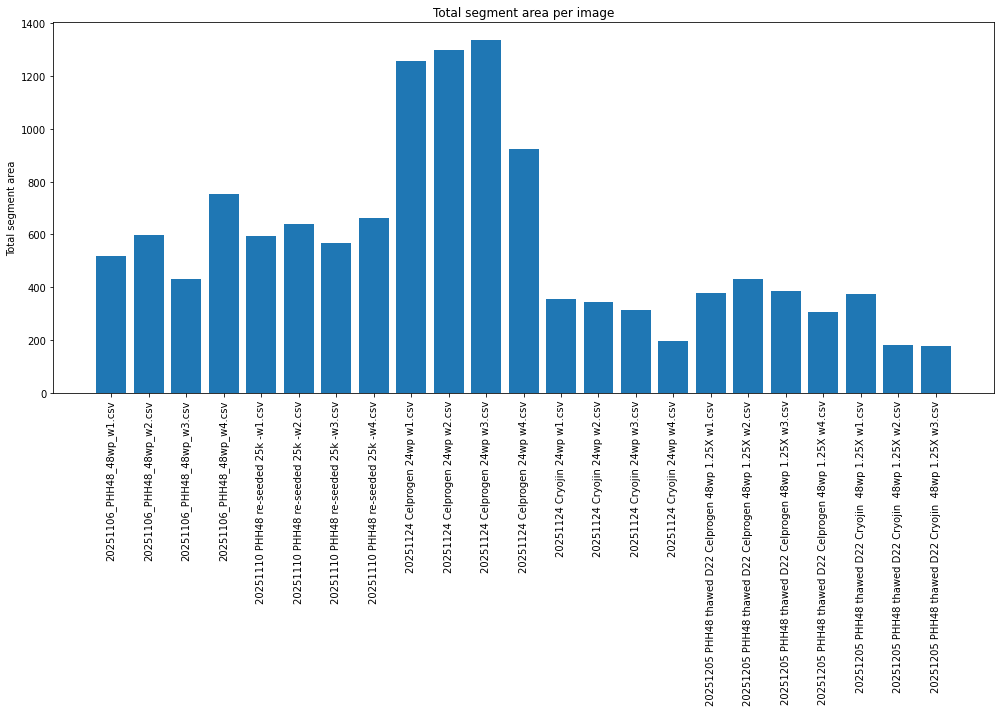

In [11]:

plt.figure(figsize=(14, 10))

plt.bar(file_names, segment_counts)
plt.ylabel('Total segment area')
plt.title('Total segment area per image')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



## Outputs and interpretation

- **Per-image CSV:** one row per retained segmented object, including area, intensity statistics, and major-axis length.
- **Segmentation overlay:** detected object boundaries displayed on the source image for visual inspection.
- **Summary plots:** object counts and the original area-labeled plot (see the note above).

### Limitations

Results can be affected by low resolution, image contrast, background variation, merged objects, and the chosen size threshold. Object counts are not equivalent to OFE percentages unless the relevant number of seeded cells and experimental definitions are incorporated separately. Review overlays and experimental controls before drawing biological conclusions.

### Collaboration and acknowledgement

This analysis workflow was developed by **Ivey Sebastian** in collaboration with **Jinia Lilianty**, a postdoctoral researcher in the **Meri Huch research group**, for stereomicroscopy-based organoid quantification.

*The notebook's computational methods and execution code are unchanged from the original version.*